# Advisor brief: YouTube robot-comment analytics

Recent pipeline commits: subject topic9 labeling (kimi-k3), BERTopic validity + `reduce_topics(nr=35)`, open concepts v3, two-round canonical merge.

This notebook **reads frozen artifacts only** (no API calls, no re-clustering).

**Data pack (committed):** `notebooks/data/20261120_advisor_brief/` — slim tables so the notebook runs without the ignored full `output/` dumps.


In [1]:
from __future__ import annotations

import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import cohen_kappa_score

ROOT = Path("..").resolve()
PACK = ROOT / "notebooks/data/20261120_advisor_brief"
assert PACK.is_dir(), f"Missing data pack: {PACK}"

CORE_LABELS = ("Robot", "Imagination about Robots", "Self")
GOLD_COL = "261029_yilin"

TRACE_IDS = [
    "UgxMeH7_ybaLuHNDJEl4AaABAg",
    "UgyGyGOaECf7YNdRjbx4AaABAg",
    "Ugw5h9Sgoj-H-Vzs5It4AaABAg",
]

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})


def split_labels(value) -> list[str]:
    text = "" if value is None or (isinstance(value, float) and np.isnan(value)) else str(value).strip()
    if not text or text.lower() == "nan":
        return []
    out: list[str] = []
    for part in re.split(r"[|,]", text):
        tok = part.strip()
        if tok and tok not in out:
            out.append(tok)
    return out


def first_label(value) -> str:
    parts = split_labels(value)
    return parts[0] if parts else ""


def crosstab_table(df: pd.DataFrame, row: str, col: str) -> pd.DataFrame:
    """Cells: n (row%); margin row/col totals."""
    ct = pd.crosstab(df[row], df[col], margins=False)
    row_tot = ct.sum(axis=1)
    col_tot = ct.sum(axis=0)
    grand = int(ct.values.sum())
    out = pd.DataFrame(index=list(ct.index) + ["Total"], columns=list(ct.columns) + ["Total"], dtype=object)
    for i in ct.index:
        for j in ct.columns:
            n = int(ct.loc[i, j])
            pct = 100.0 * n / row_tot[i] if row_tot[i] else 0.0
            out.loc[i, j] = f"{n} ({pct:.1f}%)"
        out.loc[i, "Total"] = f"{int(row_tot[i])} (100.0%)"
    for j in ct.columns:
        n = int(col_tot[j])
        pct = 100.0 * n / grand if grand else 0.0
        out.loc["Total", j] = f"{n} ({pct:.1f}%)"
    out.loc["Total", "Total"] = str(grand)
    return out


def primary_cohen_kappa(wide: pd.DataFrame, pred_col: str, gold_col: str = GOLD_COL) -> tuple[int, float, float]:
    """Primary-label exact match rate and Cohen's κ (multiclass)."""
    status_col = f"{pred_col}_status"
    ev = wide[wide[status_col] == "ok"] if status_col in wide.columns else wide
    yt = ev[gold_col].map(first_label)
    yp = ev[pred_col].map(first_label)
    m = yt.ne("") & yp.ne("")
    yt, yp = yt[m], yp[m]
    if len(yt) == 0:
        return 0, float("nan"), float("nan")
    acc = float((yt == yp).mean())
    labels = sorted(set(yt) | set(yp))
    kap = float(cohen_kappa_score(yt, yp, labels=labels)) if len(labels) > 1 else float("nan")
    return int(len(yt)), acc, kap


def macro_kappa_from_by_category(by_cat: pd.DataFrame) -> tuple[float, float]:
    """Mean and n_gold-weighted mean of per-label κ_ovr (order-free per-category table)."""
    if by_cat.empty or "kappa_ovr" not in by_cat.columns:
        return float("nan"), float("nan")
    if "n_gold" in by_cat.columns:
        sub = by_cat[by_cat["n_gold"].fillna(0) > 0].copy()
    else:
        sub = by_cat.copy()
    if sub.empty or sub["kappa_ovr"].notna().sum() == 0:
        return float("nan"), float("nan")
    macro = float(sub["kappa_ovr"].mean())
    if "n_gold" in sub.columns and sub["n_gold"].sum() > 0:
        wt = float((sub["kappa_ovr"] * sub["n_gold"]).sum() / sub["n_gold"].sum())
    else:
        wt = macro
    return macro, wt


def load_prompt_excerpt(path: Path, max_lines: int = 18) -> str:
    lines = path.read_text(encoding="utf-8").splitlines()
    if lines and lines[0].strip() == "---":
        i = 1
        while i < len(lines) and lines[i].strip() != "---":
            i += 1
        lines = lines[i + 1 :]
    return "\n".join([ln for ln in lines if ln.strip()][:max_lines])


print("PACK", PACK)


PACK /Users/yilin/Desktop/project/robot_failure/notebooks/data/20261120_advisor_brief


## 1. Corpus and labeling setup

- **L1 labeled universe:** kimi-k3, prompt `20261030_subject_topic9_v1_primary_na` (10 categories, ≤2 labels, `na` alone).
- **Formal analysis gate:** English L1 comments whose labels intersect **Robot | Imagination about Robots | Self** (N = 28,096 for BERTopic).
- **Open concepts:** same gate file `youtube_l1_object_robot_imagination_self_20261119.csv` (n = 37,321).


In [2]:
labeled = pd.read_csv(PACK / "l1_subject_labels_slim.csv", dtype={"comment_id": str}, low_memory=False)
l1 = labeled[labeled["comment_level"] == 1].copy()
l1["label_list"] = l1["subject_labels"].map(split_labels)
mask_en = l1["language"].fillna("").astype(str).str.lower().eq("en")
mask_core = l1["label_list"].map(lambda xs: bool(set(CORE_LABELS).intersection(xs)))
corpus_n = int((mask_en & mask_core).sum())
gate_n = len(pd.read_csv(PACK / "gate_comments.csv", usecols=["comment_id"]))

counts = pd.DataFrame(
    [
        {"layer": "L1 all comments", "n": len(l1)},
        {"layer": "L1 English", "n": int(mask_en.sum())},
        {"layer": "L1 English ∩ {R, Imagination, Self}", "n": corpus_n},
        {"layer": "L1 gate (concept extract)", "n": gate_n},
    ]
)
display(counts)

batch = (
    l1.loc[mask_en & mask_core]
    .groupby("source_batch", dropna=False)
    .size()
    .reset_index(name="n")
)
batch["pct"] = 100.0 * batch["n"] / batch["n"].sum()
batch["n (row%)"] = batch.apply(lambda r: f"{int(r['n'])} ({r['pct']:.1f}%)", axis=1)
display(batch[["source_batch", "n (row%)"]])

display(Markdown(f"**Subject prompt (excerpt)**\n\n```\n{load_prompt_excerpt(ROOT / 'human_label_llm/prompt/20261030_subject_topic9_v1_primary_na.md')}\n```"))


,layer,n
0,L1 all comments,57547
1,L1 English,40855
2,"L1 English ∩ {R, Imagination, Self}",28096
3,L1 gate (concept extract),37321


,source_batch,n (row%)
0,2604-marathon,6794 (24.2%)
1,2608-olympic,21302 (75.8%)


**Subject prompt (excerpt)**

```
# ROLE
You are a qualitative research assistant responsible for classifying the primary topic of social media comments. Your task is to identify the topics of each comment and select one or more of the ten categories. All content is derived from the comments section of a short video featuring a robot competition.
# CATEGORY DEFINITIONS
Robot: Comments regarding the robot's appearance, movements, performance, or status. (Example: "It runs so fast; if it hits a person or car, both would be totaled...")
Event or Competition: Comments regarding the race format, the significance of the event, or specific incidents occurring during the competition. (Example: "Is this event even meaningful?")
Imagination about Robots: Comments about robots outside the current marathon context, including future applications. (Example: "When I get old, I'll count on these little robots to run errands for me.")
Other People in Videos: Comments regarding people visible in the video, such as engineers, programmers, security guards, audience members, etc. (Example: "Feeling sorry for the programmer for a second.")
Other People in Comments: Comments directed at other users in the comment section, including replies, praise, rebuttals, or mockery. (Example: "A bunch of people who have never seen the world.")
Self: Comments that center the commenter’s own experiences, abilities, identity, or sense of worth, including explicit comparisons between the commenter and a robot. This category may also include reflection on a collective self, such as “we humans,” when the focus is on human identity, ability, or worth.
Video or Media: Comments about the video itself or its presentation. (Example: "The editing makes the robot look faster than it is.")
Affiliated Organization or Country: Comments primarily about a company, institution, or country associated with the robot. (Example: "China is building t-800")
na: Comments that are advertising, traffic diversion, or subscription/promotion spam; pure insults or hate speech with no other topical content; or comments that have not been translated into English.
No Clear Subject: Comments that do not fit any of the above categories, including off-topic posts, venting, garbled text, emojis, or meaningless content. (Example: "Hahahaha")
# JUDGMENT RULES
Assign one primary label. Add a second label only when the comment independently develops a second distinct topic, and put that second label after the primary. Never assign more than two labels. Do not add a second label to hedge.
na cannot appear together with any other category. It means the comment is advertising/traffic-diversion/subscription spam, pure insult or hate speech, or not translated into English. If na applies, assign na alone. na is never a second label.
No Clear Subject cannot appear together with any other category. It means the comment has no topic that fits the other eight categories and is not na. If one of those eight applies, do not also assign No Clear Subject. If none of them applies and na does not apply, assign No Clear Subject alone. No Clear Subject is never a second label.
If a clear topic falls outside the categories, use No Clear Subject alone and suggest a new topic label in note.
```

## 2. Object labels vs human gold & Cohen's κ

**Gold:** `261029_yilin` on the 500-comment evaluation sample (n = 493 with valid pairs).

| Metric | Definition |
|--------|------------|
| **Primary acc / κ** | First label in gold vs first predicted label (Cohen's κ on multiclass primary). |
| **Any-hit** | Order-free set overlap (share of comments with ≥1 shared label). |
| **Macro κ** | Mean of per-label κ_ovr from `eval_by_category.csv` (one-vs-rest per codebook category). |
| **Any-hit κ** | Registry-reported Cohen's κ on order-free hit (where exported); see `eval_summary` + gold sample. |


In [3]:
RUNS = [
    ("kimi-k3", "20261116_youtube_subject_topic9_v1_primary_na_kimi_k3", "llm_kimi_k3_or_scope_comment_only"),
    ("gpt-6.1-sol", "20261030_youtube_subject_topic9_v1_primary_na_gpt61sol", "llm_gpt_61_sol_or_scope_comment_only"),
    ("gpt-6-luna", "20261030_youtube_subject_topic9_v1_primary_na_or", "llm_gpt_6_luna_or_scope_comment_only"),
    ("deepseek-v4.1-flash", "20261030_youtube_subject_topic9_v1_primary_na_or", "llm_deepseek_v41_flash_1017_or_scope_comment_only"),
]

# canonical primary κ from project registry (gpt-6.1-sol comparison_wide empty)
REGISTRY_PRIMARY = {"gpt-6.1-sol": (0.6917, 0.6201)}
# order-free hit κ from experiment registry (full gold run)
REGISTRY_ANY_HIT_KAPPA = {"kimi-k3": 0.7241}

align_rows = []
for name, run_id, pred_col in RUNS:
    run_dir = PACK / "eval" / run_id
    wide = pd.read_csv(run_dir / "comparison_wide_slim.csv")
    ev = pd.read_csv(run_dir / "eval_summary.csv")
    by_cat = pd.read_csv(run_dir / "eval_by_category.csv")
    ev_match = ev.loc[ev["pred_column"] == pred_col] if "pred_column" in ev.columns else ev.iloc[0:0]
    if len(ev_match):
        ev_row = ev_match.iloc[0]
    elif name == "deepseek-v4.1-flash":
        ev_row = ev.iloc[0]
    elif name == "gpt-6-luna":
        ev_row = ev.iloc[1] if len(ev) > 1 else ev.iloc[0]
    else:
        ev_row = ev.iloc[0]
    n, acc, pk = primary_cohen_kappa(wide, pred_col)
    if name in REGISTRY_PRIMARY and (n == 0 or np.isnan(acc)):
        acc, pk = REGISTRY_PRIMARY[name]
        n = 493
    macro_k, wt_k = macro_kappa_from_by_category(by_cat)
    align_rows.append(
        {
            "model": name,
            "n": n,
            "primary_acc": round(acc, 4),
            "primary_cohen_κ": round(pk, 4) if pk == pk else None,
            "any_hit": round(float(ev_row["any_hit"]), 4) if pd.notna(ev_row.get("any_hit")) else None,
            "any_hit_cohen_κ": REGISTRY_ANY_HIT_KAPPA.get(name),
            "exact_set": round(float(ev_row["exact_set_match"]), 4) if pd.notna(ev_row.get("exact_set_match")) else None,
            "macro_cohen_κ": round(macro_k, 4) if macro_k == macro_k else None,
            "weighted_κ_ovr": round(wt_k, 4) if wt_k == wt_k else None,
        }
    )

# Human–human primary Cohen's κ (same gold sample columns in comparison_wide)
wide0 = pd.read_csv(PACK / "eval/20261116_youtube_subject_topic9_v1_primary_na_kimi_k3/comparison_wide_slim.csv")
if "xiaoyu" in wide0.columns:
    h1, h2 = wide0[GOLD_COL].map(first_label), wide0["xiaoyu"].map(first_label)
    m = h1.ne("") & h2.ne("")
    human_k = float(cohen_kappa_score(h1[m], h2[m]))
    display(Markdown(f"**Human benchmark:** primary Cohen's κ (yilin vs xiaoyu) = **{human_k:.4f}** on overlapping sample."))

display(pd.DataFrame(align_rows))

kimi_cat = pd.read_csv(PACK / "eval/20261116_youtube_subject_topic9_v1_primary_na_kimi_k3/eval_by_category.csv")
show = kimi_cat[["category", "n_gold", "n_correct", "accuracy", "kappa_ovr"]].copy()
show = show.sort_values("n_gold", ascending=False)
display(Markdown("**kimi-k3 — per-category recall (accuracy) and Cohen's κ_ovr**"))
display(show.round(4))


**Human benchmark:** primary Cohen's κ (yilin vs xiaoyu) = **0.6985** on overlapping sample.

,model,n,primary_acc,primary_cohen_κ,any_hit,any_hit_cohen_κ,exact_set,macro_cohen_κ,weighted_κ_ovr
0,kimi-k3,493,0.7302,0.6643,0.7870,0.7241,0.6389,0.6097,0.6822
1,gpt-6.1-sol,493,0.6917,0.6201,NaN,NaN,NaN,NaN,NaN
2,gpt-6-luna,493,0.6714,0.5894,0.7363,NaN,0.6268,0.5629,0.6300
3,deepseek-v4.1-flash,493,0.6592,0.5848,0.7241,NaN,0.5842,0.5629,0.6300


**kimi-k3 — per-category recall (accuracy) and Cohen's κ_ovr**

,category,n_gold,n_correct,accuracy,kappa_ovr
6,Robot,170,129,0.7588,0.6641
3,No Clear Subject,106,84,0.7925,0.6312
0,Affiliated Organization or Country,75,68,0.9067,0.8827
2,Imagination about Robots,70,54,0.7714,0.7683
7,Self,45,29,0.6444,0.6005
1,Event or Competition,40,27,0.6750,0.5682
8,Video or Media,12,8,0.6667,0.6050
5,Other People in Videos,7,4,0.5714,0.4616
4,Other People in Comments,5,3,0.6000,0.3054
9,na,0,0,NaN,0.0000


In [4]:
corpus = pd.read_csv(PACK / "analysis_corpus_slim.csv", dtype={"comment_id": str})
sent = pd.read_csv(PACK / "sentiment_scores.csv", dtype={"comment_id": str})
ana = corpus.merge(sent, on="comment_id", how="inner")
if "char_len" not in ana.columns:
    ana["char_len"] = 0

label_rows = []
for _, row in ana.iterrows():
    for lab in split_labels(row["subject_labels"]):
        if lab in CORE_LABELS or lab == "No Clear Subject":
            label_rows.append(
                {
                    "comment_id": row["comment_id"],
                    "label": lab,
                    "source_batch": row["source_batch"],
                    "char_len": row["char_len"],
                    "sentiment": row["sentiment"],
                }
            )
lab_long = pd.DataFrame(label_rows)

freq = (
    lab_long.groupby("label")
    .agg(n=("comment_id", "count"), median_len=("char_len", "median"), mean_len=("char_len", "mean"))
    .reset_index()
    .sort_values("n", ascending=False)
)
freq["pct"] = 100.0 * freq["n"] / freq["n"].sum()
freq["n (share%)"] = freq.apply(lambda r: f"{int(r['n'])} ({r['pct']:.1f}%)", axis=1)
display(freq[["label", "n (share%)", "median_len", "mean_len"]].round(1))

display(Markdown("**Sentiment × subject label**"))
display(crosstab_table(lab_long, "label", "sentiment"))

display(Markdown("**Sentiment × video batch**"))
display(crosstab_table(ana, "source_batch", "sentiment"))

ana["len_bin"] = pd.cut(ana["char_len"], bins=[0, 40, 120, 400, 10_000], labels=["≤40", "41–120", "121–400", ">400"])
display(Markdown("**Length bin × sentiment**"))
display(crosstab_table(ana, "len_bin", "sentiment"))

tri = ana[["comment_id", "has_robot", "has_imagination", "has_self"]].drop_duplicates("comment_id")
tri["combo"] = tri.apply(
    lambda r: "+".join([name for name, col in [("R", "has_robot"), ("I", "has_imagination"), ("S", "has_self")] if r[col]]),
    axis=1,
)
combo = tri["combo"].value_counts().reset_index()
combo.columns = ["combo", "n"]
combo["pct"] = 100.0 * combo["n"] / combo["n"].sum()
combo["n (share%)"] = combo.apply(lambda r: f"{int(r['n'])} ({r['pct']:.1f}%)", axis=1)
display(Markdown("**Core-label co-occurrence (comment-level)**"))
display(combo[["combo", "n (share%)"]])


,label,n (share%),median_len,mean_len
2,Robot,14267 (43.7%),54.0,77.4
0,Imagination about Robots,12520 (38.3%),68.0,98.4
3,Self,5891 (18.0%),73.0,103.9
1,No Clear Subject,1 (0.0%),884.0,884.0


**Sentiment × subject label**

,negative,neutral,positive,Total
Imagination about Robots,5839 (46.6%),4928 (39.4%),1753 (14.0%),12520 (100.0%)
No Clear Subject,1 (100.0%),0 (0.0%),0 (0.0%),1 (100.0%)
Robot,5410 (37.9%),6256 (43.8%),2601 (18.2%),14267 (100.0%)
Self,3194 (54.2%),1698 (28.8%),999 (17.0%),5891 (100.0%)
Total,14444 (44.2%),12882 (39.4%),5353 (16.4%),32679


**Sentiment × video batch**

,negative,neutral,positive,Total
2604-marathon,2731 (40.2%),2909 (42.8%),1154 (17.0%),6794 (100.0%)
2608-olympic,9271 (43.5%),8607 (40.4%),3424 (16.1%),21302 (100.0%)
Total,12002 (42.7%),11516 (41.0%),4578 (16.3%),28096


**Length bin × sentiment**

,negative,neutral,positive,Total
≤40,2734 (32.0%),4418 (51.8%),1383 (16.2%),8535 (100.0%)
41–120,6484 (44.7%),5677 (39.1%),2352 (16.2%),14513 (100.0%)
121–400,2580 (55.6%),1283 (27.6%),779 (16.8%),4642 (100.0%)
>400,204 (50.2%),138 (34.0%),64 (15.8%),406 (100.0%)
Total,12002 (42.7%),11516 (41.0%),4578 (16.3%),28096


**Core-label co-occurrence (comment-level)**

,combo,n (share%)
0,R,11836 (42.1%)
1,I,9751 (34.7%)
2,I+S,2151 (7.7%)
3,S,1927 (6.9%)
4,R+S,1813 (6.5%)
5,R+I,618 (2.2%)


## 3. Topics: HDBSCAN 60 vs `reduce_topics(nr=35)`

Validity layer: ~60 topics, outlier ≈41.5%. Reporting layer: 34 topics after `nr=35` (max C_V in 12–35 scan). Outlier count unchanged.

Perspective **shares** = each label's non-outlier comments assigned to topic t / all non-outliers for that label.


In [5]:
topics60 = pd.read_csv(PACK / "topics60.csv")
topics35 = pd.read_csv(PACK / "topics_nr35.csv")
doc60 = pd.read_csv(PACK / "doc_topics60.csv", dtype={"comment_id": str})
n_out = int((doc60["topic"] == -1).sum())
n_all = len(doc60)
display(
    pd.DataFrame(
        [
            {"layer": "HDBSCAN mcs80", "n_topics": int((topics60.Topic >= 0).sum()), "outlier_pct": round(100 * n_out / n_all, 1)},
            {"layer": "reduce nr35", "n_topics": int((topics35.Topic >= 0).sum()), "outlier_pct": round(100 * n_out / n_all, 1)},
        ]
    )
)

TOPIC_LABEL = {0: "China / geopolitics", 1: "Usain Bolt / records", 2: "Guns and weapons", 3: "Terminator", 6: "End of humanity", 8: "Remote control", 9: "Skynet", 11: "Jobs and replacement"}

shares60 = pd.read_csv(PACK / "topic_prop_shares_by_perspective.csv")
shares60["topic_label"] = shares60["topic_id"].map(lambda t: TOPIC_LABEL.get(int(t), f"topic {int(t)}"))
shares60["Imgn_minus_Robot"] = shares60["share_Imagination"] - shares60["share_Robot"]
top = shares60.sort_values("Imgn_minus_Robot", ascending=False).head(12)
for c in ["share_Robot", "share_Imagination", "share_Self"]:
    top[c] = (100 * top[c]).round(1)
display(Markdown("**HDBSCAN 60 — topic occupancy (% of each perspective's non-outliers)**"))
display(top[["topic_id", "topic_label", "share_Robot", "share_Imagination", "share_Self", "Imgn_minus_Robot"]])

doc35 = pd.read_csv(PACK / "doc_topics_nr35.csv", dtype={"comment_id": str})
m = corpus.merge(doc35.rename(columns={"topic": "topic_id"}), on="comment_id", how="inner")
m = m[m["topic_id"] != -1]


def perspective_shares_nr35(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for pers, col in [("Robot", "has_robot"), ("Imagination", "has_imagination"), ("Self", "has_self")]:
        base = df[df[col] == True]
        tot = len(base)
        for tid, g in base.groupby("topic_id"):
            rows.append({"topic_id": int(tid), "perspective": pers, "share": len(g) / tot if tot else 0.0})
    return pd.DataFrame(rows).pivot(index="topic_id", columns="perspective", values="share").reset_index()


sh35 = perspective_shares_nr35(m)
name_map = dict(zip(topics35.Topic, topics35.Name.astype(str)))
sh35["topic_label"] = sh35["topic_id"].map(lambda t: name_map.get(t, str(t)).split("_", 1)[-1][:48])
sh35["Imgn_minus_Robot"] = sh35["Imagination"] - sh35["Robot"]
top35 = sh35.sort_values("Imgn_minus_Robot", ascending=False).head(12)
for c in ["Robot", "Imagination", "Self"]:
    top35[c] = (100 * top35[c]).round(1)
display(Markdown("**After reduce nr35 (34 topics)**"))
display(top35[["topic_id", "topic_label", "Robot", "Imagination", "Self", "Imgn_minus_Robot"]])


,layer,n_topics,outlier_pct
0,HDBSCAN mcs80,60,41.5
1,reduce nr35,34,41.5


**HDBSCAN 60 — topic occupancy (% of each perspective's non-outliers)**

,topic_id,topic_label,share_Robot,share_Imagination,share_Self,Imgn_minus_Robot
2,2,Guns and weapons,0.8,11.4,3.0,0.105782
3,3,Terminator,1.4,10.4,3.6,0.090010
9,9,Skynet,0.3,6.8,1.5,0.065063
11,11,Jobs and replacement,0.7,4.9,3.9,0.042196
15,15,topic 15,0.2,3.5,1.1,0.032633
6,6,End of humanity,0.7,3.9,12.4,0.031573
14,14,topic 14,0.7,3.3,3.2,0.025581
22,22,topic 22,0.3,2.2,0.4,0.018943
16,16,topic 16,0.8,2.6,1.2,0.018139
7,7,topic 7,2.6,4.4,3.3,0.017925


**After reduce nr35 (34 topics)**

perspective,topic_id,topic_label,Robot,Imagination,Self,Imgn_minus_Robot
2,2,terminator_terminators_the_movies,0.8,11.4,3.0,0.105782
3,3,guns_military_they_them,1.4,10.4,3.6,0.090010
9,9,scary_terrifying_this_creepy,0.3,6.8,1.5,0.065063
11,11,laugh_laughing_now_funny,0.7,4.9,3.9,0.042196
15,15,future_years_year_10,0.2,3.5,1.1,0.032633
6,6,skynet_is_coming_the,0.7,3.9,12.4,0.031573
14,14,laundry_fold_my_folding,0.7,3.3,3.2,0.025581
22,22,800_1000_t1000_t800,0.3,2.2,0.4,0.018943
16,16,anime_naruto_girl_run,0.8,2.6,1.2,0.018139
7,7,he_bro_me_drunk,2.6,4.4,3.3,0.017925


## 4. Open concepts → canonical merge (kimi-k3)

Not axial / selective coding — synonym consolidation only (`20261120_concept_merge_v1`). gpt-oss runs listed for scale comparison only.


In [6]:
display(Markdown(
    f"**Extract** (`20261119_open_concepts_v3`)\n\n```\n{load_prompt_excerpt(ROOT / 'human_label_llm/prompt/20261119_open_concepts_v3.md', 14)}\n```\n\n"
    f"**Merge** (`20261120_concept_merge_v1`)\n\n```\n{load_prompt_excerpt(ROOT / 'human_label_llm/prompt/20261120_concept_merge_v1.md', 16)}\n```"
))

long = pd.read_csv(PACK / "concepts_long.csv", dtype={"comment_id": str})
mapping = pd.read_csv(PACK / "concept_mapping_slim.csv")
c1 = pd.read_csv(PACK / "clusters_r1.csv")
c2 = pd.read_csv(PACK / "clusters_r2.csv")

display(
    pd.DataFrame(
        [
            {"stage": "mentions (raw)", "count": len(long), "unique_labels": int(long["concept_raw"].nunique())},
            {"stage": "C1", "count": int(c1["n_members"].sum()), "unique_labels": len(c1)},
            {"stage": "C2", "count": int(c2["n_members"].sum()), "unique_labels": len(c2)},
        ]
    )
)

for title, series in [
    ("raw Top10", long["concept_raw"].value_counts().head(10)),
    ("C1 Top10", c1.sort_values("n_members", ascending=False).head(10).set_index("canon_id")["canonical"]),
    ("C2 Top10", c2.sort_values("n_members", ascending=False).head(10).set_index("canon_id")["canonical"]),
]:
    display(Markdown(f"**{title}**"))
    tbl = series.reset_index()
    tbl.columns = ["id", "label"] if len(tbl.columns) == 2 else tbl.columns
    display(tbl)

# gpt-oss scale (registry / local full runs if present)
oss_rows = [
    {"model": "gpt-oss-20b", "mentions": 87736, "unique_raw": 69321},
    {"model": "gpt-oss-120b", "mentions": 87391, "unique_raw": 74066},
]
for tag, sub in [
    ("gpt-oss-20b", "20261119_youtube_l1_open_concepts_v3_robot_imagination_self_gpt_oss_20b"),
    ("gpt-oss-120b", "20261119_youtube_l1_open_concepts_v3_robot_imagination_self_gpt_oss_120b"),
]:
    p = ROOT / "output/concept_extract" / sub / "concepts_long.csv"
    if p.exists():
        cl = pd.read_csv(p)
        for r in oss_rows:
            if r["model"] == tag:
                r["mentions"] = len(cl)
                r["unique_raw"] = int(cl["concept_raw"].nunique())
display(pd.DataFrame(oss_rows))
display(Markdown("_Contrast:_ kimi phrases vs gpt-oss single-token heads (`robot`, `Skynet`)."))


**Extract** (`20261119_open_concepts_v3`)

```
# INPUT
<comment>{comment}</comment>
```

**Merge** (`20261120_concept_merge_v1`)

```
# INPUT
Consolidate the following open codes (JSON array). Each string must appear in exactly one cluster.
```json
{concepts_json}
```
```

,stage,count,unique_labels
0,mentions (raw),91489,79895
1,C1,79895,42170
2,C2,42113,26367


**raw Top10**

,id,label
0,rewarding a robot,114
1,Terminator reference,95
2,we're cooked,73
3,amused reaction,71
4,scary,70
5,remote controlled toys,56
6,creepy,52
7,remote controlled,50
8,robots replacing humans,48
9,Skynet,48


**C1 Top10**

,id,label
0,C1_34786,AI takeover and human obsolescence
1,C1_40130,fear of the future
2,C1_33171,robots outrunning humans
3,C1_16679,robot takeover
4,C1_28843,robot apocalypse fear
5,C1_39037,fear of AI/robot apocalypse
6,C1_13330,technology ending up in wrong hands
7,C1_03033,Skynet / robot uprising
8,C1_06860,robots/AI destroying humanity
9,C1_35674,AI takeover fear


**C2 Top10**

,id,label
0,C2_21442,sarcastic or joking remarks
1,C2_20517,AI takeover apocalypse fear
2,C2_09541,robot apocalypse beginning
3,C2_14434,AI takeover and existential threat
4,C2_11960,AI apocalypse / takeover
5,C2_10433,apprehension about future military technology
6,C2_09879,weight distribution and movement capacity
7,C2_24301,dismissive or hostile reaction
8,C2_18240,sarcastic and ironic commentary
9,C2_13638,metal being's agility


,model,mentions,unique_raw
0,gpt-oss-20b,87736,69321
1,gpt-oss-120b,87391,74066


_Contrast:_ kimi phrases vs gpt-oss single-token heads (`robot`, `Skynet`).

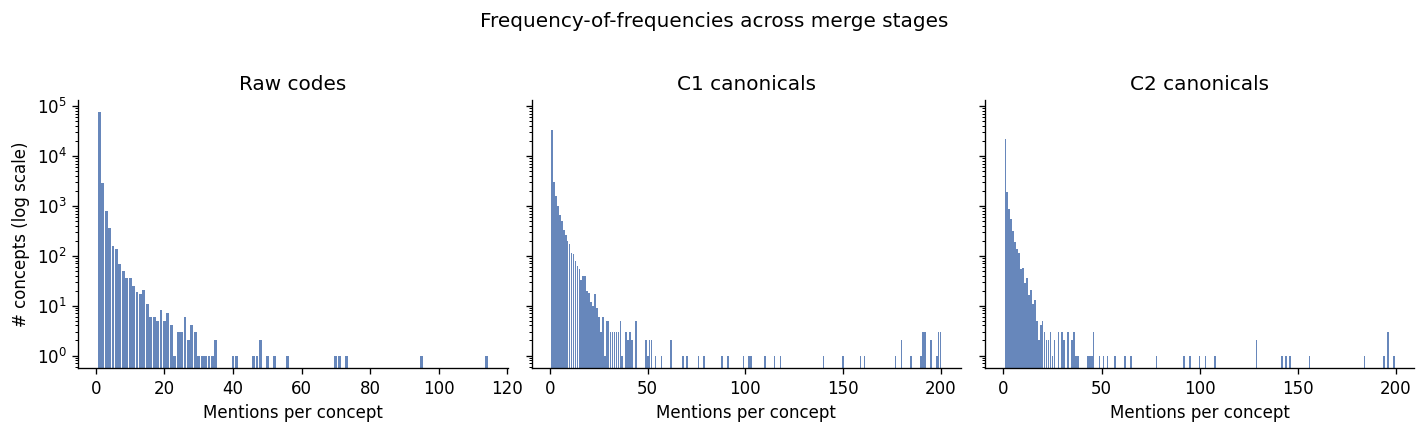

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (title, vc) in zip(
    axes,
    [
        ("Raw codes", long["concept_raw"].value_counts()),
        ("C1 canonicals", c1.set_index("canonical")["n_members"]),
        ("C2 canonicals", c2.set_index("canonical")["n_members"]),
    ],
):
    hist = vc.value_counts().sort_index()
    ax.bar(hist.index, hist.values, width=0.85, color="#4C72B0", alpha=0.85)
    ax.set_yscale("log")
    ax.set_xlabel("Mentions per concept")
    ax.set_title(title)
axes[0].set_ylabel("# concepts (log scale)")
fig.suptitle("Frequency-of-frequencies across merge stages", y=1.02)
plt.tight_layout()
plt.show()


In [8]:
gate = pd.read_csv(PACK / "gate_comments.csv", dtype={"comment_id": str})
hit = long.merge(mapping[["concept_raw", "canonical_r2"]], on="concept_raw", how="left")
hit = hit.merge(gate[["comment_id", "subject_labels"]], on="comment_id", how="left")
for core in CORE_LABELS:
    sub = hit[hit["subject_labels"].fillna("").map(lambda s: core in split_labels(s))]
    top = sub["canonical_r2"].value_counts().head(8).reset_index()
    top.columns = ["canonical_r2", "mention_rows"]
    display(Markdown(f"**Top C2 on `{core}` comments**"))
    display(top)


**Top C2 on `Robot` comments**

,canonical_r2,mention_rows
0,remote-controlled not autonomous,708
1,AI takeover apocalypse fear,298
2,robot speed and performance,234
3,sarcastic or joking remarks,207
4,humor and mockery,200
5,robots outrunning humans,193
6,robot performance and speed,187
7,AI takeover and existential threat,185


**Top C2 on `Imagination about Robots` comments**

,canonical_r2,mention_rows
0,modifying robots for war,1362
1,Terminator reference,709
2,military weaponization of robots,688
3,AI takeover fear,313
4,AI takeover apocalypse fear,307
5,AI uprising and robot takeover,252
6,Skynet reference,236
7,AI apocalypse / takeover,225


**Top C2 on `Self` comments**

,canonical_r2,mention_rows
0,AI takeover fear,143
1,modifying robots for war,136
2,AI takeover apocalypse fear,125
3,AI takeover reference,124
4,robots replacing humans,123
5,AI uprising and robot takeover,120
6,AI takeover and existential threat,113
7,AI apocalypse / takeover,105


In [9]:
comments = pd.read_csv(PACK / "trace_comments.csv", dtype={"comment_id": str})


def audit_chain(raw: str, c1: str, c2: str) -> str:
    if str(raw).lower() == str(c2).lower():
        return "meaning kept"
    if str(raw).lower() == str(c1).lower() and c1 != c2:
        return "widened at C2"
    if len(str(c2)) > len(str(raw)) + 12:
        return "widened label"
    if str(c2).lower() not in str(raw).lower() and str(raw).lower() not in str(c2).lower():
        return "check nuance / possible drift"
    return "consolidated"


def trace_comment(cid: str) -> None:
    text = comments.loc[comments.comment_id == cid, "content_en"]
    text = text.iloc[0] if len(text) else ""
    display(Markdown(f"### Trace `{cid}`\n\n{text[:600]}"))
    raws = long.loc[long.comment_id == cid, "concept_raw"].tolist()
    if not raws:
        display(Markdown("_No concepts in gate subset._"))
        return
    rows = mapping[mapping.concept_raw.isin(raws)]
    for _, row in rows.iterrows():
        verdict = audit_chain(row["concept_raw"], row["canonical_r1"], row["canonical_r2"])
        ex = mapping[mapping.canonical_r2 == row["canonical_r2"]].sort_values("n_mentions", ascending=False).iloc[0]
        display(
            Markdown(
                f"- `{row['concept_raw']}` → **{row['canonical_r1']}** → **{row['canonical_r2']}** — *{verdict}*. "
                f"Example: \"{ex['concept_raw'][:120]}\"."
            )
        )


for cid in TRACE_IDS:
    trace_comment(cid)


### Trace `UgxMeH7_ybaLuHNDJEl4AaABAg`

I can’t believe I am living to see the beginnings of The Terminator in real life.

- `Terminator beginning in real life` → **Terminator reference** → **Terminator reference** — *check nuance / possible drift*. Example: "I, Robot reference".

- `living to see The Terminator` → **waiting for Terminator** → **AI conspiring to eradicate humanity** — *check nuance / possible drift*. Example: "Skynet is already here".

### Trace `UgyGyGOaECf7YNdRjbx4AaABAg`

This is actually terrifying. The marching robot platoon is a look into the future when they will be carrying weapons.

- `fear of robotic militarization` → **fear of robotic militarization** → **fear of robotic militarization** — *meaning kept*. Example: "AI-powered robot knights".

- `future weaponized robots` → **military weaponization of robots** → **modifying robots for war** — *check nuance / possible drift*. Example: "robot soldiers".

- `marching robot platoon` → **military robot deployment and cost-driven labor** → **AI taking human jobs** — *check nuance / possible drift*. Example: "robots replacing human workers".

### Trace `Ugw5h9Sgoj-H-Vzs5It4AaABAg`

How about if the robot's body covered with light silicone to appear like human😮

- `human-like robot appearance` → **robot design and engineering details** → **robot design and engineering details** — *check nuance / possible drift*. Example: "human-like robot appearance".

- `light silicone robot body` → **light silicone robot body** → **light silicone robot body** — *meaning kept*. Example: "light silicone robot body".